# 36103 Statistical Thinking for Data Science
## Assessment Task 3: Data analysis project for marketing campaigns (code)

**Student:** Quang Trung Nguyen (26643559)

This notebook produces every number, table and figure in the AT3 report. It runs from top to bottom with `data.csv` in the same folder. Figures are saved to `figures/` and tables to `tables/`.

### Contents
1. Setup and data loading
2. Data quality checks and cleaning (with changes made after AT1 feedback)
3. Statistical tests of association
4. Train/test split
5. Parametric model: logistic regression estimated by maximum likelihood (MLE)
6. Non-parametric models: KNN, decision tree and gradient boosting
7. Model comparison (cross-validation, hold-out test, temporal validation)
8. Interpretation of the non-parametric model
9. Bayesian estimation (Module 3): Beta-Binomial segment rates and Bayesian logistic regression with MCMC
10. Business insight calculations
11. Fairness check used in the ethics section

## 1. Setup and data loading

In [1]:
# !pip install pandas numpy scipy statsmodels scikit-learn matplotlib
import io
import os
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance, partial_dependence
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
                             precision_score, recall_score, f1_score, roc_curve,
                             precision_recall_curve)
from sklearn.model_selection import (StratifiedKFold, GridSearchCV, cross_val_predict,
                                     train_test_split)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.base import clone

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

SEED = 42
os.makedirs("figures", exist_ok=True)
os.makedirs("tables", exist_ok=True)

# Chart style: one text colour, light grid, fixed colour order for series
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e5e4e0"
C_BLUE, C_ORANGE, C_AQUA, C_YELLOW, C_GREY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 9,
    "axes.edgecolor": INK2, "axes.labelcolor": INK, "axes.titlesize": 10,
    "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "legend.frameon": False, "lines.linewidth": 2,
})

def save(fig, name):
    fig.savefig(f"figures/{name}.png", bbox_inches="tight", facecolor="white")
    plt.show()

In [2]:
# The raw file wraps each row in quotes and doubles the inner quotes (same repair as AT1)
PATH = "data.csv"
with open(PATH, encoding="utf-8-sig") as f:
    lines = f.read().splitlines()
fixed = []
for line in lines:
    line = line.rstrip("\r\n")
    if line.startswith('"') and line.endswith('"'):
        line = line[1:-1]
    fixed.append(line.replace('""', '"'))
raw = pd.read_csv(io.StringIO("\n".join(fixed)), sep=";", quotechar='"')
print("Raw shape:", raw.shape)
raw.head()

Raw shape: (41180, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,45,services,married,basic.9y,unknown,no,no,telephone,may,mon,198,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,59,admin.,married,professional.course,no,no,no,telephone,may,mon,139,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,41,blue-collar,married,unknown,unknown,no,no,telephone,may,mon,217,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


## 2. Data quality checks and cleaning

### 2.1 Row order is chronological
The `month` column changes in blocks (may, jun, ..., dec, mar, ...), and wraps from `dec` back to `mar` twice. This means rows are stored in time order across three campaign phases. I derive a `period` index (one value per month block) and a `phase` label before removing duplicates, so the order is kept. The original public version of this data covers May 2008 to November 2010 (Moro et al., 2014), which matches three phases.

In [3]:
raw["period"] = (raw["month"] != raw["month"].shift()).cumsum()
raw["phase"] = np.select([raw["period"] <= 7, raw["period"] <= 17], [1, 2], default=3)
raw["row_order"] = np.arange(len(raw))
print("Number of month blocks:", raw["period"].max())
print(raw.groupby("period")["month"].first().tolist())

Number of month blocks: 26
['may', 'jun', 'jul', 'aug', 'oct', 'nov', 'dec', 'mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec', 'mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov']


### 2.2 Data quality summary

In [4]:
data_cols = [c for c in raw.columns if c not in ["period", "phase", "row_order"]]
checks = {
    "Exact duplicate rows": int(raw.duplicated(subset=data_cols).sum()),
    "Age range": f"{raw['age'].min()} to {raw['age'].max()}",
    "Rows with age > 90 (removed in AT1, kept now)": int((raw["age"] > 90).sum()),
    "pdays = 999 (never contacted code)": int((raw["pdays"] == 999).sum()),
    "pdays = 999 but previous > 0 (inconsistent)": int(((raw["pdays"] == 999) & (raw["previous"] > 0)).sum()),
    "default = 'yes'": int((raw["default"] == "yes").sum()),
    "education = 'illiterate'": int((raw["education"] == "illiterate").sum()),
    "housing and loan both 'unknown' (same rows)": int(((raw["housing"] == "unknown") & (raw["loan"] == "unknown")).sum()),
    "Target prevalence (yes)": round((raw["y"] == "yes").mean(), 4),
}
pd.Series(checks, name="value").to_frame()

,value
Exact duplicate rows,12
Age range,17 to 98
"Rows with age > 90 (removed in AT1, kept now)",10
pdays = 999 (never contacted code),39667
pdays = 999 but previous > 0 (inconsistent),4108
default = 'yes',3
education = 'illiterate',18
housing and loan both 'unknown' (same rows),990
Target prevalence (yes),0.1126


In [5]:
unknown = {c: (raw[c] == "unknown").mean() * 100 for c in raw.select_dtypes("object").columns}
pd.Series(unknown, name="% unknown").round(2).sort_values(ascending=False).to_frame()

,% unknown
default,20.87
education,4.20
housing,2.40
loan,2.40
job,0.80
marital,0.19
contact,0.00
month,0.00
day_of_week,0.00
poutcome,0.00


### 2.3 Why the age > 90 records are kept (AT1 feedback)
AT1 removed 10 records with age above 90. The marker pointed out that these ages are plausible and that older customers are one of the most responsive groups. The table below confirms it: the 10 records subscribed at 50%, and the 65+ group subscribes at about four times the overall rate. All ages are kept in AT3.

In [6]:
tmp = raw.drop_duplicates(subset=data_cols)
tmp_target = (tmp["y"] == "yes").astype(int)
print("Subscription rate, age > 90:", round(tmp_target[tmp["age"] > 90].mean(), 3), "n =", int((tmp["age"] > 90).sum()))
print(tmp_target.groupby(pd.cut(tmp["age"], [16, 24, 34, 44, 54, 64, 74, 100])).agg(["size", "mean"]).round(3))

Subscription rate, age > 90: 0.5 n = 10
            size   mean
age                    
(16, 24]    1067  0.240
(24, 34]   13684  0.122
(34, 44]   13492  0.086
(44, 54]    8701  0.086
(54, 64]    3563  0.136
(64, 74]     392  0.441
(74, 100]    269  0.520


### 2.4 Leakage check on `duration`
`duration` is only known after the call ends, and a zero-second call is always a "no". The quick check below shows how much it inflates performance. It is excluded from all models.

In [7]:
quick = tmp.copy()
quick["target"] = tmp_target
cat_q = ["job", "marital", "education", "default", "contact", "month", "day_of_week", "poutcome"]
num_q = ["age", "campaign", "euribor3m", "cons.price.idx", "cons.conf.idx"]
def quick_auc(num_cols):
    pre = ColumnTransformer([("c", OneHotEncoder(handle_unknown="ignore"), cat_q), ("n", StandardScaler(), num_cols)])
    pipe = Pipeline([("p", pre), ("m", LogisticRegression(max_iter=3000))])
    p = cross_val_predict(pipe, quick[cat_q + num_cols], quick["target"],
                          cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method="predict_proba")[:, 1]
    return roc_auc_score(quick["target"], p)
leak_with, leak_without = quick_auc(num_q + ["duration"]), quick_auc(num_q)
print(f"5-fold ROC-AUC with duration: {leak_with:.3f}; without duration: {leak_without:.3f}")

5-fold ROC-AUC with duration: 0.932; without duration: 0.787


### 2.5 Multicollinearity of the economic indicators
AT1 found correlations above 0.9 between the macroeconomic indicators. Variance inflation factors (VIF) confirm it. I keep one indicator of the labour/interest-rate cycle plus the two price and confidence indices. The choice between `euribor3m` and `nr.employed` is made by AIC in Section 5.

In [8]:
def vif_table(frame, cols):
    X = sm.add_constant(frame[cols])
    return pd.Series({c: variance_inflation_factor(X.values, i + 1) for i, c in enumerate(cols)}, name="VIF").round(1)
macro_all = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
vif_all = vif_table(tmp, macro_all)
vif_kept_eur = vif_table(tmp, ["cons.price.idx", "cons.conf.idx", "euribor3m"])
vif_kept_nemp = vif_table(tmp, ["cons.price.idx", "cons.conf.idx", "nr.employed"])
pd.concat([vif_all.rename("All five"), vif_kept_eur.rename("Kept (euribor3m)"), vif_kept_nemp.rename("Kept (nr.employed)")], axis=1)

,All five,Kept (euribor3m),Kept (nr.employed)
emp.var.rate,32.9,NaN,NaN
cons.price.idx,6.3,2.0,1.4
cons.conf.idx,2.6,1.1,1.0
euribor3m,63.9,2.1,NaN
nr.employed,30.8,NaN,1.4


### 2.6 Cleaning and feature preparation

| Step | Reason |
|---|---|
| Remove 12 duplicate rows | Exact copies would be counted twice |
| Keep all ages | Plausible values and a high-response group (AT1 feedback) |
| Drop `duration` | Target leakage |
| Drop `pdays` | 96% coded 999, and 4,108 rows have `pdays = 999` while `previous > 0`; `poutcome` holds the same information without the conflict |
| `default`: flag `default_unk` = 1 if not "no" | Only 3 "yes" values, all non-subscribers (would cause separation) |
| Merge `illiterate` (n = 18) into `basic.4y` for modelling | Too few cases to estimate a coefficient |
| Drop `housing` and `loan` | Their "unknown" rows are the same 990 records (perfect collinearity) and neither is associated with the target (chi-square tests below) |
| Age groups for the logistic model | Response is U-shaped in age (tested in Section 5) |
| `log2_campaign` | Contact count is right-skewed; the coefficient reads as the effect of doubling the number of calls |
| Keep "unknown" as its own level elsewhere | "unknown" is informative (e.g. `default` unknown subscribes at 5.2% vs 12.9%) |

In [9]:
df = raw.drop_duplicates(subset=data_cols).copy().reset_index(drop=True)
df["target"] = (df["y"] == "yes").astype(int)
df["default_unk"] = (df["default"] != "no").astype(int)
df["edu"] = df["education"].replace({"illiterate": "basic.4y"})
df[["age", "campaign"]] = df[["age", "campaign"]].astype(float)
df["log2_campaign"] = np.log2(df["campaign"])
AGE_BINS, AGE_LABELS = [16, 24, 34, 44, 54, 64, 120], ["17-24", "25-34", "35-44", "45-54", "55-64", "65+"]
df["age_grp"] = pd.cut(df["age"], AGE_BINS, labels=AGE_LABELS).astype(str)
df = df.rename(columns={"cons.price.idx": "cpi", "cons.conf.idx": "cci", "nr.employed": "nr_employed",
                        "emp.var.rate": "emp_var_rate"})
print("Clean shape:", df.shape, "| subscription rate:", round(df["target"].mean(), 4))

Clean shape: (41168, 29) | subscription rate: 0.1126


## 3. Statistical tests of association (AT1 feedback: no formal tests)
Chi-square tests of independence for categorical predictors (with Cramér's V as effect size) and Mann-Whitney U tests for numeric predictors, because the numeric variables are skewed.

In [10]:
rows = []
for c in ["poutcome", "month", "job", "contact", "default", "education", "marital", "day_of_week", "housing", "loan"]:
    t = pd.crosstab(df[c], df["target"])
    chi2, p, dof, _ = stats.chi2_contingency(t)
    v = np.sqrt(chi2 / (t.values.sum() * (min(t.shape) - 1)))
    rows.append({"variable": c, "test": "Chi-square", "statistic": round(chi2, 1), "df": dof, "p_value": p, "effect_size": round(v, 3)})
for c in ["age", "campaign", "euribor3m", "nr_employed", "cpi", "cci"]:
    a, b = df.loc[df.target == 1, c], df.loc[df.target == 0, c]
    u = stats.mannwhitneyu(a, b)
    r_rb = 1 - 2 * u.statistic / (len(a) * len(b))  # rank-biserial correlation
    rows.append({"variable": c, "test": "Mann-Whitney U", "statistic": round(u.statistic, 0), "df": np.nan, "p_value": u.pvalue, "effect_size": round(abs(r_rb), 3)})
tests = pd.DataFrame(rows)
tests["p_value"] = tests["p_value"].map(lambda p: "<0.001" if p < 0.001 else f"{p:.3f}")
tests.to_csv("tables/association_tests.csv", index=False)
tests

,variable,test,statistic,df,p_value,effect_size
0,poutcome,Chi-square,4217.7,2.0,<0.001,0.320
1,month,Chi-square,3103.7,9.0,<0.001,0.275
2,job,Chi-square,960.0,11.0,<0.001,0.153
3,contact,Chi-square,860.8,1.0,<0.001,0.145
4,default,Chi-square,406.2,2.0,<0.001,0.099
5,education,Chi-square,192.4,7.0,<0.001,0.068
6,marital,Chi-square,123.2,3.0,<0.001,0.055
7,day_of_week,Chi-square,26.0,4.0,<0.001,0.025
8,housing,Chi-square,5.8,2.0,0.056,0.012
9,loan,Chi-square,1.1,2.0,0.584,0.005


### 3.1 Segment-level interaction (AT1 feedback: correlation matrix only)
Cross-tabulated rates for age group by contact channel, and previous outcome by channel. These raw patterns suggest interactions; Section 5 tests them formally inside the logistic model.

In [11]:
print(pd.crosstab(df["age_grp"], df["contact"], values=df["target"], aggfunc="mean").round(3))
print(pd.crosstab(df["poutcome"], df["contact"], values=df["target"], aggfunc="mean").round(3))

contact  cellular  telephone
age_grp                     
17-24       0.285      0.087
25-34       0.154      0.058
35-44       0.115      0.046
45-54       0.113      0.045
55-64       0.179      0.058
65+         0.490      0.338
contact      cellular  telephone
poutcome                        
failure         0.145      0.113
nonexistent     0.117      0.047
success         0.651      0.641


### 3.2 Campaign phase and call volume
The high rates in March, September, October and December found in AT1 come from later, low-volume months. The table shows rate and volume per month block.

In [12]:
per = df.groupby("period").agg(phase=("phase", "first"), month=("month", "first"), calls=("target", "size"),
                               rate=("target", "mean"), euribor=("euribor3m", "mean")).round(3)
rho, p_rho = stats.spearmanr(per["calls"], per["rate"])
print(f"Spearman correlation between monthly call volume and subscription rate: rho = {rho:.2f}, p = {p_rho:.2g}")
phase_tab = df.groupby("phase").agg(calls=("target", "size"), rate=("target", "mean"),
                                    calls_per_month=("period", lambda s: len(s) / s.nunique()),
                                    euribor_mean=("euribor3m", "mean"), cellular_share=("contact", lambda s: (s == "cellular").mean())).round(3)
phase_tab.to_csv("tables/phase_summary.csv")
print(phase_tab)
per

Spearman correlation between monthly call volume and subscription rate: rho = -0.67, p = 0.00019
       calls   rate  calls_per_month  euribor_mean  cellular_share
phase                                                             
1      27678  0.048         3954.000         4.817           0.505
2      11436  0.195         1143.600         1.232           0.918
3       2054  0.521          228.222         0.813           0.811


,phase,month,calls,rate,euribor
period,,,,,
1,1,may,7758,0.031,4.858
2,1,jun,4374,0.043,4.932
3,1,jul,6681,0.061,4.962
4,1,aug,5173,0.052,4.965
5,1,oct,67,0.627,4.924
6,1,nov,3615,0.053,4.115
7,1,dec,10,0.100,3.493
8,2,mar,282,0.447,1.646
9,2,apr,2457,0.180,1.412


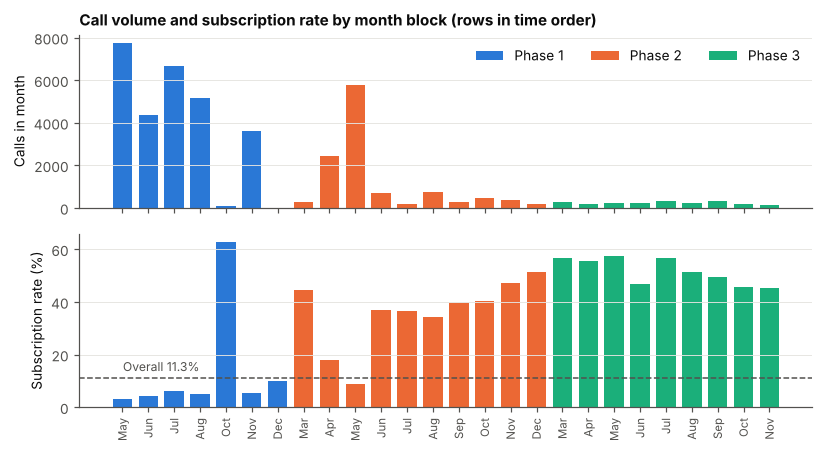

In [13]:
# Figure: call volume and subscription rate for each month block, coloured by phase (two panels, no dual axis)
phase_col = {1: C_BLUE, 2: C_ORANGE, 3: C_AQUA}
xs = np.arange(len(per))
fig, axes = plt.subplots(2, 1, figsize=(8.6, 4.4), sharex=True, gridspec_kw={"hspace": 0.15})
for ph in [1, 2, 3]:
    m = per["phase"].values == ph
    axes[0].bar(xs[m], per["calls"].values[m], color=phase_col[ph], width=0.75, label=f"Phase {ph}")
    axes[1].bar(xs[m], per["rate"].values[m] * 100, color=phase_col[ph], width=0.75)
axes[0].set_ylabel("Calls in month")
axes[1].set_ylabel("Subscription rate (%)")
axes[1].axhline(df["target"].mean() * 100, color=INK2, linestyle="--", linewidth=1)
axes[1].text(1.5, df["target"].mean() * 100 + 2.5, f"Overall {df['target'].mean():.1%}", ha="center", fontsize=8, color=INK2)
axes[1].set_xticks(xs); axes[1].set_xticklabels(per["month"].str.title(), rotation=90, fontsize=7.5)
axes[0].legend(loc="upper right", ncol=3)
axes[0].set_title("Call volume and subscription rate by month block (rows in time order)", loc="left")
for a in axes: a.grid(axis="x", visible=False)
save(fig, "fig1_phase_volume")

## 4. Train/test split
Stratified 80/20 split. All model selection, tuning and cross-validation use the training set only. The test set is used once at the end.

In [14]:
train, test = train_test_split(df, test_size=0.2, stratify=df["target"], random_state=SEED)
print("Train:", train.shape, round(train.target.mean(), 4), "| Test:", test.shape, round(test.target.mean(), 4))

Train: (32934, 29) 0.1126 | Test: (8234, 29) 0.1126


## 5. Parametric model: logistic regression (MLE)

The response is binary, so a Bernoulli GLM with a logit link is the natural parametric model (Lecture 2/3). Coefficients are estimated by maximum likelihood (Lecture 5): `statsmodels` minimises the negative log-likelihood, which is convex for logistic regression, so the solution is the global optimum.

Model selection is done by building the model in blocks and comparing nested models with likelihood-ratio tests (LRT), AIC and BIC.

In [15]:
J = 'C(job, Treatment("admin."))'
E = 'C(edu, Treatment("university.degree"))'
A = 'C(age_grp, Treatment("35-44"))'
P = 'C(poutcome, Treatment("nonexistent"))'
M = 'C(month, Treatment("may"))'
forms = {}
forms["M1 customer profile"] = f"target ~ {A} + {J} + C(marital) + {E} + default_unk"
forms["M2 + contact history"] = forms["M1 customer profile"] + f" + C(contact) + {P} + log2_campaign"
forms["M3 + economy"] = forms["M2 + contact history"] + " + nr_employed + cpi + cci"
forms["M4 + timing"] = forms["M3 + economy"] + f" + {M} + C(day_of_week)"
forms["M4 using euribor3m"] = forms["M4 + timing"].replace("nr_employed", "euribor3m")
forms["M5 + contact x previous outcome"] = forms["M4 + timing"] + f" + C(contact):{P}"
forms["M6 + contact x age group"] = forms["M4 + timing"] + f" + C(contact):{A}"
forms["M4 without age"] = forms["M4 + timing"].replace(f"{A} + ", "")
forms["M4 with linear age"] = forms["M4 + timing"].replace(A, "age")
forms["M4 with age + age^2"] = forms["M4 + timing"].replace(A, "age + I(age**2)")

fits = {k: smf.logit(f, data=train).fit(disp=0, maxiter=300) for k, f in forms.items()}
sel = pd.DataFrame({k: {"parameters": int(r.df_model) + 1, "log_lik": r.llf, "AIC": r.aic, "BIC": r.bic,
                        "McFadden_R2": r.prsquared} for k, r in fits.items()}).T.round(3)

def lrt(small, big):
    stat = 2 * (fits[big].llf - fits[small].llf)
    ddf = fits[big].df_model - fits[small].df_model
    return stat, int(ddf), stats.chi2.sf(stat, ddf)

lrt_rows = []
for s_, b_ in [("M1 customer profile", "M2 + contact history"), ("M2 + contact history", "M3 + economy"),
               ("M3 + economy", "M4 + timing"), ("M4 + timing", "M5 + contact x previous outcome"),
               ("M4 + timing", "M6 + contact x age group"), ("M4 without age", "M4 + timing"),
               ("M4 with linear age", "M4 with age + age^2")]:
    st, dd, pv = lrt(s_, b_)
    lrt_rows.append({"comparison": f"{s_}  ->  {b_}", "LR_chi2": round(st, 1), "df": dd, "p_value": pv})
lrt_tab = pd.DataFrame(lrt_rows)
sel.to_csv("tables/logit_model_selection.csv")
lrt_tab.to_csv("tables/logit_lrt.csv", index=False)
print(sel[["parameters", "AIC", "BIC", "McFadden_R2"]])
print(lrt_tab)
lrt_tab

                                 parameters        AIC        BIC  McFadden_R2
M1 customer profile                    27.0  21961.224  22188.085        0.055
M2 + contact history                   31.0  20142.459  20402.929        0.134
M3 + economy                           34.0  18816.378  19102.054        0.191
M4 + timing                            47.0  18484.411  18879.318        0.207
M4 using euribor3m                     47.0  18504.357  18899.263        0.206
M5 + contact x previous outcome        49.0  18488.288  18899.999        0.207
M6 + contact x age group               52.0  18487.142  18924.060        0.207
M4 without age                         42.0  18488.023  18840.918        0.206
M4 with linear age                     43.0  18489.937  18851.234        0.206
M4 with age + age^2                    44.0  18478.515  18848.215        0.207
                                         comparison  LR_chi2  df        p_value
0     M1 customer profile  ->  M2 + contact history

,comparison,LR_chi2,df,p_value
0,M1 customer profile -> M2 + contact history,1826.8,4,0.000000e+00
1,M2 + contact history -> M3 + economy,1332.1,3,1.609614e-288
2,M3 + economy -> M4 + timing,358.0,13,1.634414e-68
3,M4 + timing -> M5 + contact x previous outcome,0.1,2,9.400390e-01
4,M4 + timing -> M6 + contact x age group,7.3,5,2.013836e-01
5,M4 without age -> M4 + timing,13.6,5,1.827740e-02
6,M4 with linear age -> M4 with age + age^2,13.4,1,2.486833e-04


**Selection result.** Each block (contact history, economy, timing) improves fit (LRT p < 0.001 for every step). In the full model, `nr_employed` gives an AIC about 20 points lower than `euribor3m`, so it represents the economic cycle. Neither interaction is supported: contact by previous outcome is not significant and contact by age group is borderline, and both raise BIC. The final parametric model is therefore **M4**.

Age: the LRT for `age^2` confirms a curved (U-shaped) effect, and age groups beat linear age on AIC. A quadratic in age has a slightly lower AIC than age groups (about 6 points), but it forces a symmetric U-shape and gives coefficients a marketing team cannot read as segments. I keep age groups because the business question is about segments; the cost in fit is small.

In [16]:
final_formula = forms["M4 + timing"]
logit_fit = fits["M4 + timing"]
print(logit_fit.summary2())

                                                Results: Logit
Model:                             Logit                           Method:                          MLE       
Dependent Variable:                target                          Pseudo R-squared:                0.207     
Date:                              2026-10-28 12:54                AIC:                             18484.4115
No. Observations:                  32934                           BIC:                             18879.3177
Df Model:                          46                              Log-Likelihood:                  -9195.2   
Df Residuals:                      32887                           LL-Null:                         -11593.   
Converged:                         1.0000                          LLR p-value:                     0.0000    
No. Iterations:                    8.0000                          Scale:                           1.0000    
-------------------------------------------------

### 5.1 Assumption checks
* **Independence:** each row is a separate customer contact; duplicates removed.
* **Multicollinearity:** VIFs of the design matrix (below).
* **Linearity in the logit:** handled with age groups and `log2_campaign` (tested above).
* **Sample size:** smallest events-per-parameter is large (about 3,700 subscribers in train for 47 parameters).
* **Calibration:** Hosmer-Lemeshow style decile table on the test set in Section 7.

In [17]:
Xd = pd.DataFrame(logit_fit.model.exog, columns=logit_fit.model.exog_names)
vif_design = pd.Series({c: variance_inflation_factor(Xd.values, i) for i, c in enumerate(Xd.columns) if c != "Intercept"}).round(2)
print("Largest VIFs in the final design matrix:")
print(vif_design.sort_values(ascending=False).head(8))
print("Events in training set:", int(train.target.sum()), "| parameters:", int(logit_fit.df_model) + 1)

Largest VIFs in the final design matrix:
C(contact)[T.telephone]                       3.30
nr_employed                                   3.18
C(marital)[T.single]                          2.90
C(month, Treatment("may"))[T.aug]             2.89
cpi                                           2.84
C(marital)[T.married]                         2.61
C(job, Treatment("admin."))[T.blue-collar]    2.43
C(month, Treatment("may"))[T.jul]             2.33
dtype: float64
Events in training set: 3710 | parameters: 47


### 5.2 Odds ratios with 95% confidence intervals

In [18]:
or_tab = pd.DataFrame({"coef": logit_fit.params, "OR": np.exp(logit_fit.params),
                       "CI_low": np.exp(logit_fit.conf_int()[0]), "CI_high": np.exp(logit_fit.conf_int()[1]),
                       "p_value": logit_fit.pvalues})
def clean_name(n):
    for a, b in [('C(age_grp, Treatment("35-44"))[T.', "Age "), ('C(job, Treatment("admin."))[T.', "Job: "),
                 ('C(edu, Treatment("university.degree"))[T.', "Education: "), ('C(poutcome, Treatment("nonexistent"))[T.', "Previous outcome: "),
                 ('C(month, Treatment("may"))[T.', "Month: "), ("C(day_of_week)[T.", "Day: "), ("C(contact)[T.", "Contact: "),
                 ("C(marital)[T.", "Marital: "), ("]", "")]:
        n = n.replace(a, b)
    return n
or_tab.index = [clean_name(i) for i in or_tab.index]
or_tab = or_tab.drop(index="Intercept")
or_tab.round(4).to_csv("tables/logit_odds_ratios.csv")
or_tab.round(3)

,coef,OR,CI_low,CI_high,p_value
Age 17-24,0.264,1.302,1.034,1.639,0.025
Age 25-34,0.126,1.134,1.023,1.258,0.017
Age 45-54,0.090,1.094,0.972,1.231,0.135
Age 55-64,0.165,1.179,1.004,1.386,0.045
Age 65+,0.392,1.479,1.112,1.968,0.007
Job: blue-collar,-0.126,0.881,0.758,1.024,0.100
Job: entrepreneur,0.007,1.007,0.799,1.269,0.955
Job: housemaid,-0.076,0.927,0.701,1.225,0.592
Job: management,-0.022,0.978,0.830,1.152,0.788
Job: retired,0.157,1.170,0.928,1.476,0.185


In [19]:
# Odds ratios for scaled economic terms (per 100 fewer employed; per 1 point of the index)
econ = pd.DataFrame({
    "nr_employed (per 100 lower)": np.exp(-100 * logit_fit.params["nr_employed"]),
    "cpi (per 1 point higher)": np.exp(logit_fit.params["cpi"]),
    "cci (per 1 point higher)": np.exp(logit_fit.params["cci"]),
}, index=["OR"]).T
econ["CI_low"] = [np.exp(-100 * logit_fit.conf_int().loc["nr_employed", 1]), np.exp(logit_fit.conf_int().loc["cpi", 0]), np.exp(logit_fit.conf_int().loc["cci", 0])]
econ["CI_high"] = [np.exp(-100 * logit_fit.conf_int().loc["nr_employed", 0]), np.exp(logit_fit.conf_int().loc["cpi", 1]), np.exp(logit_fit.conf_int().loc["cci", 1])]
econ.round(3)

,OR,CI_low,CI_high
nr_employed (per 100 lower),2.869,2.685,3.066
cpi (per 1 point higher),0.982,0.904,1.066
cci (per 1 point higher),1.020,1.009,1.030


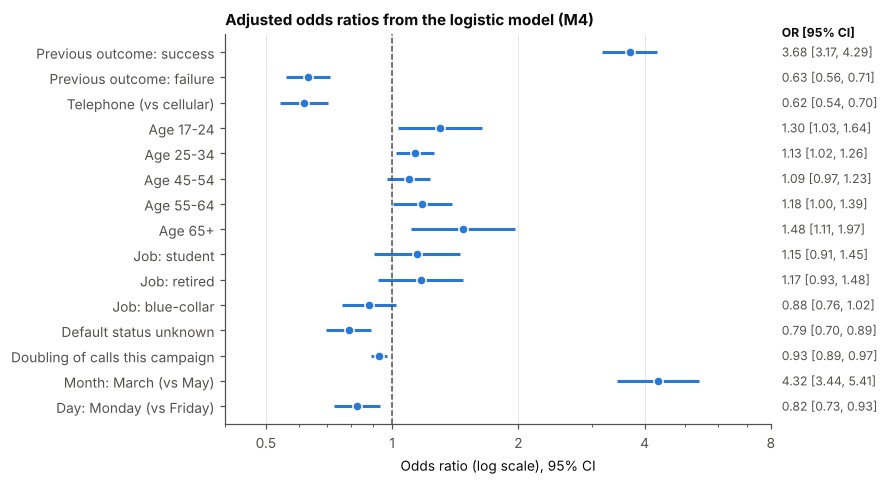

In [20]:
# Figure: forest plot of selected odds ratios
keep = ["Previous outcome: success", "Previous outcome: failure", "Contact: telephone", "Age 17-24", "Age 25-34",
        "Age 45-54", "Age 55-64", "Age 65+", "Job: student", "Job: retired", "Job: blue-collar", "default_unk",
        "log2_campaign", "Month: mar", "Day: mon"]
labels = {"default_unk": "Default status unknown", "log2_campaign": "Doubling of calls this campaign",
          "Contact: telephone": "Telephone (vs cellular)", "Month: mar": "Month: March (vs May)",
          "Day: mon": "Day: Monday (vs Friday)"}
fp = or_tab.loc[keep].iloc[::-1]
fig, ax = plt.subplots(figsize=(6.4, 4.6))
y = np.arange(len(fp))
ax.hlines(y, fp["CI_low"], fp["CI_high"], color=C_BLUE, linewidth=2)
ax.plot(fp["OR"], y, "o", color=C_BLUE, markersize=6, markeredgecolor="white", markeredgewidth=1)
ax.axvline(1, color=INK2, linewidth=1, linestyle="--")
ax.set_xscale("log")
ax.set_xticks([0.25, 0.5, 1, 2, 4, 8]); ax.set_xticklabels(["0.25", "0.5", "1", "2", "4", "8"])
ax.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
ax.set_xlim(0.4, 8)
ax.set_yticks(y); ax.set_yticklabels([labels.get(i, i) for i in fp.index])
ax.set_xlabel("Odds ratio (log scale), 95% CI")
ax.grid(axis="y", visible=False)
ax.set_title("Adjusted odds ratios from the logistic model (M4)", loc="left")
trans = matplotlib.transforms.blended_transform_factory(ax.transAxes, ax.transData)
ax.text(1.02, len(fp) - 0.4, "OR [95% CI]", transform=trans, fontsize=8, color=INK, fontweight="bold")
for yi, (o, l, h) in zip(y, fp[["OR", "CI_low", "CI_high"]].values):
    ax.text(1.02, yi, f"{o:.2f} [{l:.2f}, {h:.2f}]", transform=trans, va="center", fontsize=8, color=INK2)
save(fig, "fig4_odds_ratios")

## 6. Non-parametric models

All three models use the **same predictors** as the logistic model (raw `age` and `campaign` instead of the transformed versions, because these models learn non-linear shapes themselves). Differences in performance therefore come from model form, not from extra information.

* **KNN:** classifies by the subscription share among the k closest customers. Needs scaling. Tuned: k and weighting.
* **Decision tree:** produces readable segment rules. Tuned: depth and minimum leaf size.
* **Gradient boosting** (`HistGradientBoostingClassifier`): an ensemble of shallow trees, each fitted to the errors of the earlier trees. Tuned: learning rate, tree depth, leaf size and L2 penalty. The number of trees is set by early stopping (stop when the loss on a 10% internal validation split has not improved for 30 rounds, maximum 1,000 trees).

Tuning uses 5-fold stratified cross-validation on the training set with ROC-AUC as the score, because the business use is ranking customers for calls. No resampling is used for the class imbalance: probabilities stay calibrated, and the decision threshold is tuned instead.

In [21]:
CAT = ["job", "marital", "edu", "default_unk", "contact", "month", "day_of_week", "poutcome"]
NUM = ["age", "campaign", "nr_employed", "cpi", "cci"]
CAT_LOGIT = ["age_grp", "job", "marital", "edu", "contact", "month", "day_of_week", "poutcome"]
NUM_LOGIT = ["default_unk", "log2_campaign", "nr_employed", "cpi", "cci"]
Xtr, Xte, ytr, yte = train, test, train["target"].values, test["target"].values
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def ohe(drop=None):
    return OneHotEncoder(handle_unknown="ignore", drop=drop, sparse_output=False)

pipes = {
    "Logistic regression": Pipeline([("pre", ColumnTransformer([("c", ohe("first"), CAT_LOGIT), ("n", StandardScaler(), NUM_LOGIT)])),
                                     ("m", LogisticRegression(penalty=None, max_iter=5000))]),
    "KNN": Pipeline([("pre", ColumnTransformer([("c", ohe(), CAT), ("n", StandardScaler(), NUM)])),
                     ("m", KNeighborsClassifier())]),
    "Decision tree": Pipeline([("pre", ColumnTransformer([("c", ohe(), CAT), ("n", "passthrough", NUM)])),
                               ("m", DecisionTreeClassifier(random_state=SEED))]),
    "Gradient boosting": Pipeline([("pre", ColumnTransformer([("c", ohe(), CAT), ("n", "passthrough", NUM)])),
                                   ("m", HistGradientBoostingClassifier(max_iter=1000, early_stopping=True, validation_fraction=0.1,
                                                                        n_iter_no_change=30, random_state=SEED))]),
}
grids = {
    "Logistic regression": {},
    "KNN": {"m__n_neighbors": [100, 200, 400, 800, 1600], "m__weights": ["uniform", "distance"]},
    "Decision tree": {"m__max_depth": [4, 6, 8, 10], "m__min_samples_leaf": [50, 100, 200, 400]},
    "Gradient boosting": {"m__learning_rate": [0.05, 0.1], "m__max_depth": [2, 3, 5],
                          "m__min_samples_leaf": [100, 300, 1000], "m__l2_regularization": [1.0, 10.0, 30.0]},
}
best = {}
tuning_rows = []
for name, pipe in pipes.items():
    t0 = time.time()
    gs = GridSearchCV(pipe, grids[name] or {"m__max_iter": [5000]}, scoring="roc_auc", cv=cv, n_jobs=-1, refit=True)
    gs.fit(Xtr, ytr)
    best[name] = gs.best_estimator_
    bp = {k.replace("m__", ""): v for k, v in gs.best_params_.items()} if grids[name] else "none (MLE)"
    if name == "Gradient boosting":
        bp["trees_after_early_stopping"] = int(gs.best_estimator_.named_steps["m"].n_iter_)
    scores = gs.cv_results_["mean_test_score"]
    tuning_rows.append({"model": name, "grid_size": len(gs.cv_results_["params"]), "best_params": bp,
                        "cv_auc_best": round(gs.best_score_, 4), "cv_auc_worst_in_grid": round(scores.min(), 4),
                        "seconds": round(time.time() - t0, 1)})
tuning = pd.DataFrame(tuning_rows)
tuning.to_csv("tables/tuning.csv", index=False)
tuning

,model,grid_size,best_params,cv_auc_best,cv_auc_worst_in_grid,seconds
0,Logistic regression,1,none (MLE),0.7839,0.7839,2.1
1,KNN,10,"{'n_neighbors': 800, 'weights': 'uniform'}",0.7826,0.7501,64.4
2,Decision tree,16,"{'max_depth': 6, 'min_samples_leaf': 100}",0.7798,0.7742,6.1
3,Gradient boosting,54,"{'l2_regularization': 30.0, 'learning_rate': 0...",0.7916,0.7870,343.5


## 7. Model comparison
### 7.1 Cross-validated metrics on the training set
Out-of-fold predictions from the same 5 folds give ROC-AUC, PR-AUC (average precision; the no-skill value equals the 11.3% base rate) and Brier score. The F1-optimal threshold is chosen from the out-of-fold predictions and then fixed for the test set.

In [22]:
def fold_scores(model):
    aucs, aps, briers = [], [], []
    oof = np.zeros(len(ytr))
    for tr_i, va_i in cv.split(Xtr, ytr):
        m = clone_fit(model, Xtr.iloc[tr_i], ytr[tr_i])
        p = m.predict_proba(Xtr.iloc[va_i])[:, 1]
        oof[va_i] = p
        aucs.append(roc_auc_score(ytr[va_i], p)); aps.append(average_precision_score(ytr[va_i], p)); briers.append(brier_score_loss(ytr[va_i], p))
    return np.array(aucs), np.array(aps), np.array(briers), oof

def clone_fit(model, X, y):
    m = clone(model); m.fit(X, y); return m

def best_threshold(y, p):
    pr, rc, th = precision_recall_curve(y, p)
    f1 = 2 * pr * rc / (pr + rc + 1e-12)
    return th[np.argmax(f1[:-1])]

cv_rows, oof_preds, thresholds = [], {}, {}
for name, model in best.items():
    aucs, aps, briers, oof = fold_scores(model)
    oof_preds[name] = oof
    thresholds[name] = best_threshold(ytr, oof)
    cv_rows.append({"model": name, "CV ROC-AUC": f"{aucs.mean():.3f} ({aucs.std():.3f})",
                    "CV PR-AUC": f"{aps.mean():.3f} ({aps.std():.3f})", "CV Brier": f"{briers.mean():.4f}",
                    "threshold": round(thresholds[name], 3), "auc_mean": aucs.mean(), "auc_folds": aucs})
cv_tab = pd.DataFrame(cv_rows)
cv_tab[["model", "CV ROC-AUC", "CV PR-AUC", "CV Brier", "threshold"]]

,model,CV ROC-AUC,CV PR-AUC,CV Brier,threshold
0,Logistic regression,0.784 (0.011),0.439 (0.017),0.0796,0.199
1,KNN,0.783 (0.008),0.407 (0.018),0.0824,0.169
2,Decision tree,0.780 (0.010),0.427 (0.021),0.0790,0.210
3,Gradient boosting,0.792 (0.008),0.455 (0.022),0.0783,0.211


In [23]:
# Paired comparison of fold AUCs (same folds for every model)
auc_folds = {r["model"]: r["auc_folds"] for r in cv_rows}
for other in ["KNN", "Decision tree", "Gradient boosting"]:
    d = auc_folds[other] - auc_folds["Logistic regression"]
    t_stat, p_val = stats.ttest_rel(auc_folds[other], auc_folds["Logistic regression"])
    print(f"{other:18s} minus logistic: mean AUC difference = {d.mean():+.4f}, paired t = {t_stat:.2f}, p = {p_val:.3f}")

KNN                minus logistic: mean AUC difference = -0.0013, paired t = -0.65, p = 0.553
Decision tree      minus logistic: mean AUC difference = -0.0041, paired t = -1.55, p = 0.196
Gradient boosting  minus logistic: mean AUC difference = +0.0077, paired t = 4.31, p = 0.013


### 7.2 Hold-out test set

In [24]:
test_pred = {name: m.predict_proba(Xte)[:, 1] for name, m in best.items()}
def top_capture(y, p, frac):
    k = int(np.ceil(frac * len(p)))
    idx = np.argsort(-p)[:k]
    return y[idx].sum() / y.sum(), y[idx].mean()
test_rows = []
for name, p in test_pred.items():
    yhat = (p >= thresholds[name]).astype(int)
    cap20, prec20 = top_capture(yte, p, 0.2)
    test_rows.append({"model": name, "Test ROC-AUC": roc_auc_score(yte, p), "Test PR-AUC": average_precision_score(yte, p),
                      "Brier": brier_score_loss(yte, p), "Precision": precision_score(yte, yhat), "Recall": recall_score(yte, yhat),
                      "F1": f1_score(yte, yhat), "Top-20% capture": cap20, "Top-20% hit rate": prec20})
test_tab = pd.DataFrame(test_rows).set_index("model").round(3)
test_tab.to_csv("tables/test_metrics.csv")
test_tab

,Test ROC-AUC,Test PR-AUC,Brier,Precision,Recall,F1,Top-20% capture,Top-20% hit rate
model,,,,,,,,
Logistic regression,0.800,0.462,0.077,0.448,0.586,0.508,0.648,0.365
KNN,0.799,0.434,0.080,0.450,0.577,0.506,0.654,0.368
Decision tree,0.797,0.450,0.076,0.464,0.586,0.518,0.636,0.358
Gradient boosting,0.807,0.477,0.076,0.472,0.591,0.525,0.660,0.372


In [25]:
# Bootstrap 95% CI for the test AUC difference (gradient boosting minus logistic)
rng = np.random.default_rng(SEED)
diffs = []
for _ in range(1000):
    i = rng.integers(0, len(yte), len(yte))
    if yte[i].min() == yte[i].max():
        continue
    diffs.append(roc_auc_score(yte[i], test_pred["Gradient boosting"][i]) - roc_auc_score(yte[i], test_pred["Logistic regression"][i]))
diffs = np.array(diffs)
boot_ci = np.percentile(diffs, [2.5, 97.5])
print(f"AUC difference GB - LR: {diffs.mean():+.4f}, 95% bootstrap CI [{boot_ci[0]:+.4f}, {boot_ci[1]:+.4f}]")

AUC difference GB - LR: +0.0073, 95% bootstrap CI [-0.0003, +0.0149]


In [26]:
# Calibration by decile of predicted risk (logistic and gradient boosting, test set)
for name in ["Logistic regression", "Gradient boosting"]:
    dec = pd.qcut(test_pred[name], 10, labels=False, duplicates="drop")
    cal = pd.DataFrame({"pred": test_pred[name], "obs": yte, "dec": dec}).groupby("dec").mean().round(3)
    hl = (((cal["obs"] - cal["pred"]) ** 2) * pd.Series(dec).value_counts().sort_index().values / (cal["pred"] * (1 - cal["pred"]))).sum()
    print(f"\n{name}: Hosmer-Lemeshow style statistic = {hl:.1f} (8 df, p = {stats.chi2.sf(hl, 8):.3f})")
    print(cal.T)


Logistic regression: Hosmer-Lemeshow style statistic = 19.9 (8 df, p = 0.011)
dec       0      1      2      3      4      5      6      7      8      9
pred  0.025  0.033  0.040  0.048  0.056  0.064  0.075  0.098  0.192  0.480
obs   0.034  0.035  0.036  0.046  0.052  0.056  0.057  0.079  0.228  0.501

Gradient boosting: Hosmer-Lemeshow style statistic = 15.0 (8 df, p = 0.058)
dec       0      1      2      3      4      5      6      7      8      9
pred  0.024  0.031  0.038  0.046  0.053  0.062  0.072  0.092  0.192  0.498
obs   0.030  0.036  0.034  0.044  0.051  0.050  0.057  0.080  0.221  0.522


### 7.3 Temporal validation (robustness check)
A random split mixes all time periods, so it can flatter the models. Because rows are in time order, I also train each tuned model on phases 1 and 2 and test it on phase 3 (the last 9 month blocks, n = 2,054). This mimics using the model on a future campaign. Every month level in phase 3 also appears in phases 1 and 2.

Two things change in phase 3: the base rate is 52% instead of 9%, and `nr_employed` falls below every value seen in training, so the models must extrapolate. Tree-based models cannot extrapolate (they predict a constant beyond the last split). As a check, I also fit versions of logistic regression and gradient boosting **without** the economic and month variables (customer and contact variables only).

In [27]:
early, late = df[df["phase"] < 3], df[df["phase"] == 3]
print(f"Train phases 1-2: n = {len(early)}, base rate = {early.target.mean():.3f}, nr_employed {early.nr_employed.min()}-{early.nr_employed.max()}")
print(f"Test phase 3:     n = {len(late)}, base rate = {late.target.mean():.3f}, nr_employed {late.nr_employed.min()}-{late.nr_employed.max()}")
temporal = {}
for name, model in best.items():
    m = clone_fit(model, early, early["target"].values)
    temporal[name] = roc_auc_score(late["target"].values, m.predict_proba(late)[:, 1])
temporal = pd.Series(temporal, name="Phase-3 ROC-AUC").round(3)

CAT_CUST = ["age_grp", "job", "marital", "edu", "contact", "day_of_week", "poutcome"]
NUM_CUST = ["default_unk", "log2_campaign"]
cust_models = {
    "Logistic regression (customer and contact only)": Pipeline([("pre", ColumnTransformer([("c", ohe("first"), CAT_CUST), ("n", StandardScaler(), NUM_CUST)])),
                                                         ("m", LogisticRegression(penalty=None, max_iter=5000))]),
    "Gradient boosting (customer and contact only)": Pipeline([("pre", ColumnTransformer([("c", ohe(), CAT_CUST), ("n", "passthrough", NUM_CUST)])),
                                                       ("m", clone(best["Gradient boosting"].named_steps["m"]))]),
}
temporal_cust = {}
for name, m in cust_models.items():
    m.fit(early, early["target"].values)
    temporal_cust[name] = round(roc_auc_score(late["target"].values, m.predict_proba(late)[:, 1]), 3)
temporal_all = pd.concat([temporal, pd.Series(temporal_cust, name="Phase-3 ROC-AUC")])
temporal_all.to_csv("tables/temporal_auc.csv")
print(temporal_all)
temporal_all

Train phases 1-2: n = 39114, base rate = 0.091, nr_employed 5017.5-5228.1
Test phase 3:     n = 2054, base rate = 0.521, nr_employed 4963.6-5008.7


Logistic regression                                0.674
KNN                                                0.602
Decision tree                                      0.697
Gradient boosting                                  0.647
Logistic regression (customer and contact only)    0.697
Gradient boosting (customer and contact only)      0.698
Name: Phase-3 ROC-AUC, dtype: float64


Logistic regression                                0.674
KNN                                                0.602
Decision tree                                      0.697
Gradient boosting                                  0.647
Logistic regression (customer and contact only)    0.697
Gradient boosting (customer and contact only)      0.698
Name: Phase-3 ROC-AUC, dtype: float64

In [28]:
summary_tab = pd.DataFrame({
    "CV ROC-AUC (sd)": cv_tab.set_index("model")["CV ROC-AUC"],
    "CV PR-AUC (sd)": cv_tab.set_index("model")["CV PR-AUC"],
    "Test ROC-AUC": test_tab["Test ROC-AUC"], "Test PR-AUC": test_tab["Test PR-AUC"],
    "Precision": test_tab["Precision"], "Recall": test_tab["Recall"], "F1": test_tab["F1"],
    "Top-20% capture": test_tab["Top-20% capture"], "Phase-3 ROC-AUC": temporal,
})
summary_tab.to_csv("tables/model_comparison.csv")
print(summary_tab.to_string())
summary_tab

                    CV ROC-AUC (sd) CV PR-AUC (sd)  Test ROC-AUC  Test PR-AUC  Precision  Recall     F1  Top-20% capture  Phase-3 ROC-AUC
Logistic regression   0.784 (0.011)  0.439 (0.017)         0.800        0.462      0.448   0.586  0.508            0.648            0.674
KNN                   0.783 (0.008)  0.407 (0.018)         0.799        0.434      0.450   0.577  0.506            0.654            0.602
Decision tree         0.780 (0.010)  0.427 (0.021)         0.797        0.450      0.464   0.586  0.518            0.636            0.697
Gradient boosting     0.792 (0.008)  0.455 (0.022)         0.807        0.477      0.472   0.591  0.525            0.660            0.647


,CV ROC-AUC (sd),CV PR-AUC (sd),Test ROC-AUC,Test PR-AUC,Precision,Recall,F1,Top-20% capture,Phase-3 ROC-AUC
Logistic regression,0.784 (0.011),0.439 (0.017),0.800,0.462,0.448,0.586,0.508,0.648,0.674
KNN,0.783 (0.008),0.407 (0.018),0.799,0.434,0.450,0.577,0.506,0.654,0.602
Decision tree,0.780 (0.010),0.427 (0.021),0.797,0.450,0.464,0.586,0.518,0.636,0.697
Gradient boosting,0.792 (0.008),0.455 (0.022),0.807,0.477,0.472,0.591,0.525,0.660,0.647


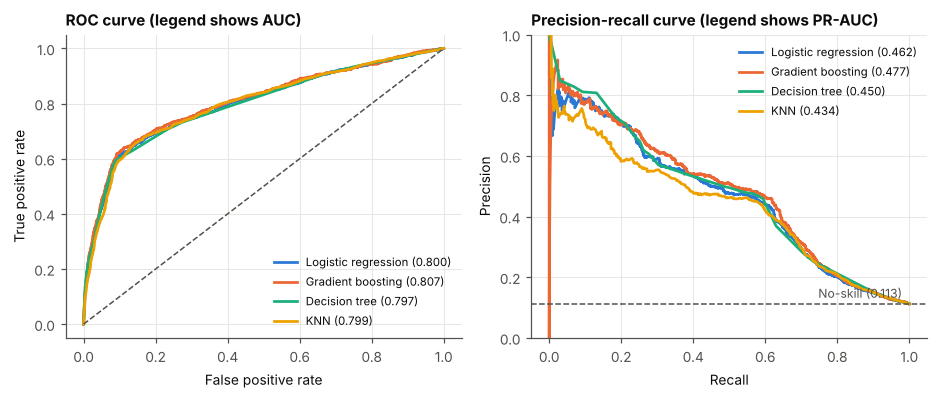

In [29]:
# Figure: ROC and precision-recall curves on the test set
colors = {"Logistic regression": C_BLUE, "Gradient boosting": C_ORANGE, "Decision tree": C_AQUA, "KNN": C_YELLOW}
fig, axes = plt.subplots(1, 2, figsize=(8.6, 3.7))
for name in ["Logistic regression", "Gradient boosting", "Decision tree", "KNN"]:
    p = test_pred[name]
    fpr, tpr, _ = roc_curve(yte, p)
    axes[0].plot(fpr, tpr, color=colors[name], label=f"{name} ({roc_auc_score(yte, p):.3f})", linewidth=1.8)
    pr, rc, _ = precision_recall_curve(yte, p)
    axes[1].plot(rc, pr, color=colors[name], label=f"{name} ({average_precision_score(yte, p):.3f})", linewidth=1.8)
axes[0].plot([0, 1], [0, 1], color=INK2, linestyle="--", linewidth=1)
axes[1].axhline(yte.mean(), color=INK2, linestyle="--", linewidth=1)
axes[1].text(0.98, yte.mean() + 0.02, f"No-skill ({yte.mean():.3f})", ha="right", fontsize=8, color=INK2)
axes[0].set(xlabel="False positive rate", ylabel="True positive rate")
axes[1].set(xlabel="Recall", ylabel="Precision", ylim=(0, 1))
axes[0].set_title("ROC curve (legend shows AUC)", loc="left")
axes[1].set_title("Precision-recall curve (legend shows PR-AUC)", loc="left")
axes[0].legend(loc="lower right", fontsize=7.5); axes[1].legend(loc="upper right", fontsize=7.5)
fig.tight_layout()
save(fig, "fig2_roc_pr")

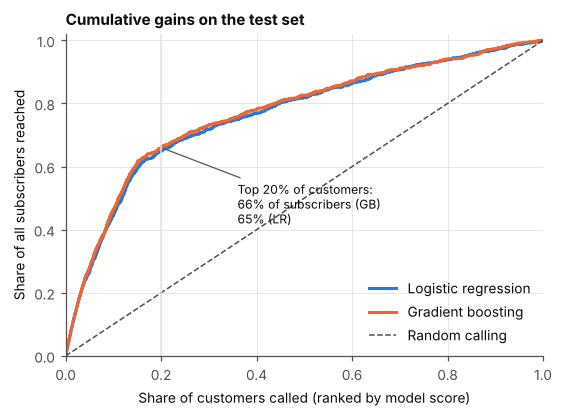

{'top 10%': {'Logistic regression': np.float64(0.446), 'Gradient boosting': np.float64(0.464)}, 'top 20%': {'Logistic regression': np.float64(0.648), 'Gradient boosting': np.float64(0.66)}, 'top 30%': {'Logistic regression': np.float64(0.718), 'Gradient boosting': np.float64(0.731)}, 'top 50%': {'Logistic regression': np.float64(0.819), 'Gradient boosting': np.float64(0.826)}}


In [30]:
# Figure: cumulative gains chart on the test set
fig, ax = plt.subplots(figsize=(5.6, 3.8))
for name in ["Logistic regression", "Gradient boosting"]:
    order = np.argsort(-test_pred[name])
    cum = np.concatenate([[0], np.cumsum(yte[order]) / yte.sum()])
    xs = np.arange(len(cum)) / len(yte)
    ax.plot(xs, cum, color=colors[name], label=name, linewidth=2)
ax.plot([0, 1], [0, 1], color=INK2, linestyle="--", linewidth=1, label="Random calling")
cap_lr, _ = top_capture(yte, test_pred["Logistic regression"], 0.2)
cap_gb, _ = top_capture(yte, test_pred["Gradient boosting"], 0.2)
cap_gb30, _ = top_capture(yte, test_pred["Gradient boosting"], 0.3)
ax.axvline(0.2, color=GRID, linewidth=1)
ax.annotate(f"Top 20% of customers:\n{cap_gb:.0%} of subscribers (GB)\n{cap_lr:.0%} (LR)", xy=(0.2, cap_gb), xytext=(0.36, 0.42),
            fontsize=8, color=INK, arrowprops=dict(arrowstyle="-", color=INK2, linewidth=0.8))
ax.set(xlabel="Share of customers called (ranked by model score)", ylabel="Share of all subscribers reached",
       xlim=(0, 1), ylim=(0, 1.02))
ax.set_title("Cumulative gains on the test set", loc="left")
ax.legend(loc="lower right")
save(fig, "fig3_gains")
print({f"top {int(f*100)}%": {n: round(top_capture(yte, test_pred[n], f)[0], 3) for n in ["Logistic regression", "Gradient boosting"]} for f in [0.1, 0.2, 0.3, 0.5]})

## 8. Interpreting the non-parametric models
### 8.1 Permutation importance (gradient boosting, test set)
Each original variable is shuffled and the drop in test ROC-AUC is measured. This works on the raw columns, so one-hot levels are grouped automatically.

In [31]:
gb = best["Gradient boosting"]
feat_cols = CAT + NUM
pi = permutation_importance(gb, Xte[feat_cols], yte, scoring="roc_auc", n_repeats=10, random_state=SEED, n_jobs=-1)
imp = pd.DataFrame({"importance": pi.importances_mean, "sd": pi.importances_std}, index=feat_cols).sort_values("importance", ascending=False)
imp.round(4).to_csv("tables/permutation_importance.csv")
imp.round(4)

,importance,sd
nr_employed,0.1174,0.0067
contact,0.0105,0.0025
cpi,0.0081,0.0025
poutcome,0.0081,0.0011
cci,0.0055,0.0011
day_of_week,0.0049,0.0007
month,0.0043,0.0017
campaign,0.0036,0.0019
age,0.0022,0.0018
default_unk,0.0019,0.0007


Partial dependence at ages 20, 40, 70: [0.129 0.102 0.137]


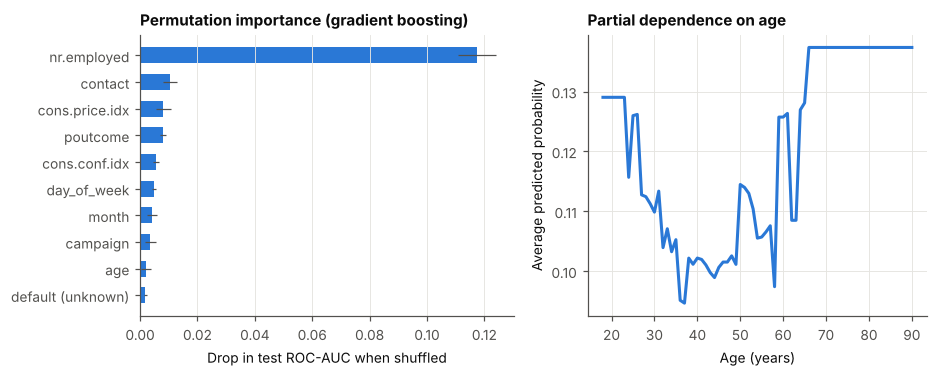

In [32]:
# Partial dependence of predicted probability on age (gradient boosting), computed over the full age range 18-90.
# For each age value, every customer in a 5,000-row training sample is given that age and the predictions are averaged.
pd_sample = Xtr[feat_cols].sample(5000, random_state=SEED)
age_grid = np.arange(18, 91, 1.0)
age_pd = []
for a_val in age_grid:
    tmp_x = pd_sample.copy()
    tmp_x["age"] = a_val
    age_pd.append(gb.predict_proba(tmp_x)[:, 1].mean())
age_pd = np.array(age_pd)
print("Partial dependence at ages 20, 40, 70:", age_pd[[2, 22, 52]].round(3))

nice = {"nr_employed": "nr.employed", "cpi": "cons.price.idx", "cci": "cons.conf.idx", "edu": "education",
        "default_unk": "default (unknown)", "day_of_week": "day_of_week"}
fig, axes = plt.subplots(1, 2, figsize=(8.6, 3.5), gridspec_kw={"width_ratios": [1.1, 1]})
top = imp.head(10).iloc[::-1]
axes[0].barh([nice.get(i, i) for i in top.index], top["importance"], color=C_BLUE, height=0.6, xerr=top["sd"],
             error_kw=dict(ecolor=INK2, elinewidth=0.8))
axes[0].set_xlabel("Drop in test ROC-AUC when shuffled")
axes[0].set_title("Permutation importance (gradient boosting)", loc="left")
axes[0].grid(axis="y", visible=False)
axes[1].plot(age_grid, age_pd, color=C_BLUE, linewidth=2)
axes[1].set(xlabel="Age (years)", ylabel="Average predicted probability")
axes[1].set_title("Partial dependence on age", loc="left")
fig.tight_layout()
save(fig, "fig5_importance_pdp")

### 8.2 Decision tree segments
The tuned tree is too deep to read, so I fit a depth-3 tree (minimum 300 customers per leaf) on the same training data to describe the main segments in plain rules.

In [33]:
tree = best["Decision tree"]
print("Tuned tree depth:", tree.named_steps["m"].get_depth(), "| leaves:", tree.named_steps["m"].get_n_leaves())
pre_tree = tree.named_steps["pre"]
Xtr_t = pre_tree.transform(Xtr)
feat_names = [n.split("__", 1)[1] for n in pre_tree.get_feature_names_out()]
small_tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=300, random_state=SEED).fit(Xtr_t, ytr)

def describe(feature, op, thr):
    for c in CAT:
        if feature.startswith(c + "_"):
            level = feature[len(c) + 1:]
            return f"{c} = {level}" if op == ">" else f"{c} != {level}"
    return f"{feature} {op} {thr:,.1f}"

def leaf_rules(clf):
    t = clf.tree_
    out = []
    def rec(node, conds):
        if t.children_left[node] == -1:
            out.append((node, conds)); return
        f, th = feat_names[t.feature[node]], t.threshold[node]
        rec(t.children_left[node], conds + [describe(f, "<=", th)])
        rec(t.children_right[node], conds + [describe(f, ">", th)])
    rec(0, [])
    return out

leaf_of = small_tree.apply(Xtr_t)
seg_rows = []
for node, conds in leaf_rules(small_tree):
    mask = leaf_of == node
    seg_rows.append({"segment rule": " AND ".join(conds), "customers": int(mask.sum()),
                     "share of customers": mask.mean(), "subscription rate": ytr[mask].mean(),
                     "share of subscribers": ytr[mask].sum() / ytr.sum()})
segments = pd.DataFrame(seg_rows).sort_values("subscription rate", ascending=False).reset_index(drop=True)
segments.round(3).to_csv("tables/tree_segments.csv", index=False)
pd.set_option("display.max_colwidth", 200)
segments.round(3)

Tuned tree depth: 6 | leaves: 36


,segment rule,customers,share of customers,subscription rate,share of subscribers
0,"nr_employed <= 5,087.7 AND poutcome = success AND cpi > 93.2",523,0.016,0.767,0.108
1,"nr_employed <= 5,087.7 AND poutcome = success AND cpi <= 93.2",380,0.012,0.642,0.066
2,"nr_employed <= 5,087.7 AND poutcome != success AND contact = cellular",2602,0.079,0.385,0.270
3,"nr_employed > 5,087.7 AND cci <= -46.6 AND poutcome != failure",1673,0.051,0.236,0.106
4,"nr_employed <= 5,087.7 AND poutcome != success AND contact != cellular",482,0.015,0.226,0.029
5,"nr_employed > 5,087.7 AND cci <= -46.6 AND poutcome = failure",496,0.015,0.111,0.015
6,"nr_employed > 5,087.7 AND cci > -46.6 AND cpi <= 94.0",17096,0.519,0.068,0.313
7,"nr_employed > 5,087.7 AND cci > -46.6 AND cpi > 94.0",9682,0.294,0.036,0.093


## 9. Bayesian estimation (Module 3)

Lecture 6 treats an unknown parameter θ as a random variable. Bayes' theorem combines the likelihood of the data with a prior distribution:

p(θ | data) ∝ p(data | θ) × p(θ), that is, posterior ∝ likelihood × prior.

Maximum likelihood (Section 5) returns the single value of θ that maximises the likelihood. Bayesian estimation returns the whole posterior distribution. A 95% credible interval from the posterior can be read as a probability statement about θ. A 95% confidence interval has no such reading: it describes how often the procedure would cover the true value over repeated samples. With a flat prior the posterior mode equals the MLE, so the two methods agree when the data are large and the prior is weak.

This section uses two Bayesian analyses. Section 9.1 uses a conjugate Beta-Binomial model for segment rates, which has a closed-form posterior. Section 9.2 uses a Bayesian logistic regression, which has no closed-form posterior, so the posterior is sampled with Markov chain Monte Carlo (MCMC).

### 9.1 Beta-Binomial model for segment subscription rates

For each segment, the subscription rate θ gets a Beta prior and the number of subscribers is Binomial given θ. The posterior is Beta(a + subscribers, b + non-subscribers) (conjugate update, Lecture 6).

* **Main prior:** weakly informative Beta centred on the overall rate (11.3%) with a prior weight of 20 customers. It pulls very small segments (e.g. `illiterate`, n = 18) toward the overall rate.
* **Sensitivity prior:** uniform Beta(1, 1), the uninformative prior from Lecture 6.

The 95% credible interval is read directly as "there is a 95% probability the segment rate lies in this range". P(θ > overall) is the posterior probability that the segment beats the average.

In [34]:
p0 = df["target"].mean()
a0, b0 = 20 * p0, 20 * (1 - p0)
def bayes_rates(col, frame=df):
    g = frame.groupby(col)["target"].agg(["size", "sum"])
    out = []
    for lvl, (n, k) in g.iterrows():
        post = stats.beta(a0 + k, b0 + n - k)
        flat = stats.beta(1 + k, 1 + n - k)
        out.append({"variable": col, "segment": lvl, "n": int(n), "observed": k / n, "posterior_mean": post.mean(),
                    "CrI_low": post.ppf(0.025), "CrI_high": post.ppf(0.975), "P(rate > overall)": 1 - post.cdf(p0),
                    "uniform_prior_CrI": f"{flat.ppf(0.025):.3f}-{flat.ppf(0.975):.3f}"})
    return pd.DataFrame(out)
bayes = pd.concat([bayes_rates(c) for c in ["age_grp", "job", "education", "poutcome", "contact"]], ignore_index=True)
bayes.round(3).to_csv("tables/bayesian_segments.csv", index=False)
bayes.round(3)

,variable,segment,n,observed,posterior_mean,CrI_low,CrI_high,P(rate > overall),uniform_prior_CrI
0,age_grp,17-24,1067,0.240,0.238,0.213,0.263,1.000,0.215-0.266
1,age_grp,25-34,13684,0.122,0.122,0.116,0.127,1.000,0.116-0.127
2,age_grp,35-44,13492,0.086,0.087,0.082,0.091,0.000,0.082-0.091
3,age_grp,45-54,8701,0.086,0.086,0.081,0.092,0.000,0.081-0.093
4,age_grp,55-64,3563,0.136,0.135,0.124,0.147,1.000,0.125-0.147
5,age_grp,65+,661,0.474,0.463,0.426,0.500,1.000,0.436-0.512
6,job,admin.,10419,0.130,0.130,0.123,0.136,1.000,0.123-0.136
7,job,blue-collar,9252,0.069,0.069,0.064,0.074,0.000,0.064-0.074
8,job,entrepreneur,1456,0.085,0.086,0.072,0.100,0.000,0.072-0.101
9,job,housemaid,1059,0.100,0.100,0.083,0.119,0.092,0.083-0.120


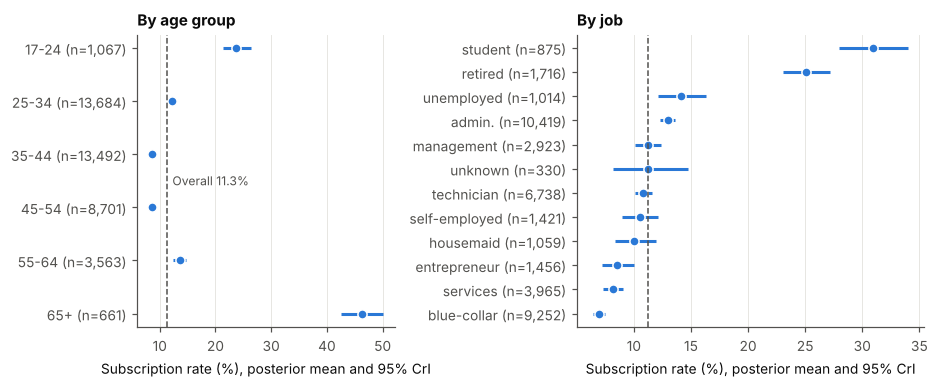

In [35]:
# Figure: posterior subscription rate by age group and job (95% credible intervals)
fig, axes = plt.subplots(1, 2, figsize=(8.6, 3.6), gridspec_kw={"width_ratios": [1, 1.35]})
for ax, col, order in [(axes[0], "age_grp", AGE_LABELS[::-1]), (axes[1], "job", None)]:
    b = bayes[bayes.variable == col].set_index("segment")
    b = b.loc[order] if order else b.sort_values("posterior_mean")
    yy = np.arange(len(b))
    ax.hlines(yy, b["CrI_low"] * 100, b["CrI_high"] * 100, color=C_BLUE, linewidth=2)
    ax.plot(b["posterior_mean"] * 100, yy, "o", color=C_BLUE, markersize=6, markeredgecolor="white")
    ax.axvline(p0 * 100, color=INK2, linestyle="--", linewidth=1)
    ax.set_yticks(yy); ax.set_yticklabels([f"{s} (n={n:,})" for s, n in zip(b.index, b["n"])])
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("Subscription rate (%), posterior mean and 95% CrI")
axes[0].text(p0 * 100 + 1, 2.5, f"Overall {p0:.1%}", fontsize=8, color=INK2, va="center")
axes[0].set_title("By age group", loc="left"); axes[1].set_title("By job", loc="left")
fig.tight_layout()
save(fig, "fig6_bayes_segments")

### 9.2 Bayesian logistic regression fitted by MCMC

**Model.** The same final model M4 as Section 5 (47 parameters, training set). The likelihood is Bernoulli with a logit link, so the log-likelihood is the one that `statsmodels` maximised. The prior is an independent Normal(0, 2.5²) on every coefficient. This is weakly informative: at 95% prior probability an odds ratio can lie anywhere from about 0.007 to 134. The four continuous predictors are standardised first so that one prior scale suits all coefficients. Results are converted back to the original units afterwards.

**Sampler.** The posterior has no closed form, so it is sampled with a random-walk Metropolis-Hastings algorithm, which follows the four steps of Lecture 6:
1. Specify the likelihood and the prior (above); the log-posterior is the log-likelihood plus the log-prior.
2. Start four chains from dispersed values (the MLE plus random noise of about three standard errors).
3. At each iteration propose a move from a multivariate Normal centred on the current value, with the MLE covariance matrix scaled by 2.38² / 47 (the rule of thumb of Roberts et al., 1997, which targets an acceptance rate near 0.234). Accept the move with probability min(1, posterior ratio); otherwise keep the current value.
4. Discard the burn-in, thin the chain, check convergence and summarise the retained draws.

Reference for the proposal scale: Roberts, G. O., Gelman, A., & Gilks, W. R. (1997). Weak convergence and optimal scaling of random walk Metropolis algorithms. *Annals of Applied Probability, 7*(1), 110-120.

**Diagnostics.** Trace plots (do the chains mix and agree), autocorrelation plots (how much information each draw adds), density plots (the posterior shape), the Gelman-Rubin statistic R-hat (below 1.01 means the chains agree) and the effective sample size (ESS).

In [36]:
Xb = pd.DataFrame(logit_fit.model.exog, columns=logit_fit.model.exog_names)
yb = train["target"].values
STD_COLS = ["nr_employed", "cpi", "cci", "log2_campaign"]
mu_b, sd_b = Xb[STD_COLS].mean(), Xb[STD_COLS].std()
Xz_df = Xb.copy()
Xz_df[STD_COLS] = (Xb[STD_COLS] - mu_b) / sd_b
Xz = Xz_df.values
mle_z = sm.Logit(yb, Xz).fit(disp=0)
print("Log-likelihood on the standardised design:", round(mle_z.llf, 3), "| same as Section 5:", round(logit_fit.llf, 3))

PRIOR_SD = 2.5
N_CHAINS, N_ITER, BURN, THIN = 4, 60000, 5000, 50

def run_mh(prior_sd, n_chains, n_iter, seed):
    """Random-walk Metropolis-Hastings for the logistic regression; all chains advance together."""
    rng = np.random.default_rng(seed)
    d = Xz.shape[1]
    chol = np.linalg.cholesky(np.asarray(mle_z.cov_params()))
    step = 2.38 / np.sqrt(d)
    def log_post(B):                      # B: chains x parameters
        eta = Xz @ B.T
        return yb @ eta - np.logaddexp(0, eta).sum(axis=0) - 0.5 * (B ** 2).sum(axis=1) / prior_sd ** 2
    B = np.asarray(mle_z.params) + 3 * (chol @ rng.standard_normal((d, n_chains))).T
    lp = log_post(B)
    draws = np.empty((n_iter, n_chains, d))
    accepted = np.zeros(n_chains)
    for t in range(n_iter):
        prop = B + step * (chol @ rng.standard_normal((d, n_chains))).T
        lp_prop = log_post(prop)
        ok = np.log(rng.random(n_chains)) < lp_prop - lp
        B[ok], lp[ok] = prop[ok], lp_prop[ok]
        accepted += ok
        draws[t] = B
    return draws, accepted / n_iter

t0 = time.time()
draws, acc_rate = run_mh(PRIOR_SD, N_CHAINS, N_ITER, SEED)
print(f"{N_CHAINS} chains x {N_ITER:,} iterations in {time.time() - t0:.0f} s | acceptance rates: {np.round(acc_rate, 3)}")

Log-likelihood on the standardised design: -9195.206 | same as Section 5: -9195.206


4 chains x 60,000 iterations in 206 s | acceptance rates: [0.237 0.241 0.242 0.239]


### 9.2.1 Convergence diagnostics

In [37]:
def acf(x, max_lag):
    x = x - x.mean()
    f = np.fft.rfft(x, 2 * len(x))
    a = np.fft.irfft(f * np.conj(f))[:max_lag + 1]
    return a / a[0]

def rhat(c):                              # c: draws x chains
    n = c.shape[0]
    w, b = c.var(axis=0, ddof=1).mean(), n * c.mean(axis=0).var(ddof=1)
    return np.sqrt(((n - 1) / n * w + b / n) / w)

def ess(c, max_lag=400):                  # c: draws x chains; sum of autocorrelations up to the first small value
    a = np.mean([acf(c[:, j], max_lag) for j in range(c.shape[1])], axis=0)
    tau = 1.0
    for lag in range(1, max_lag):
        if a[lag] < 0.05:
            break
        tau += 2 * a[lag]
    return c.shape[0] * c.shape[1] / tau

post = draws[BURN:]                       # after burn-in
kept = post[::THIN]                       # after thinning
names = list(Xb.columns)
diag = pd.DataFrame({"R_hat": [rhat(kept[:, :, j]) for j in range(len(names))],
                     "ESS_kept": [ess(kept[:, :, j]) for j in range(len(names))]}, index=names)
print(f"Draws per chain: {N_ITER:,} run, {BURN:,} burn-in, {kept.shape[0]:,} kept after thinning by {THIN}; {kept.shape[0] * N_CHAINS:,} draws in total")
print(f"Largest R-hat: {diag['R_hat'].max():.3f} | smallest ESS of the kept draws: {diag['ESS_kept'].min():.0f} | median ESS: {diag['ESS_kept'].median():.0f}")

Draws per chain: 60,000 run, 5,000 burn-in, 1,100 kept after thinning by 50; 4,400 draws in total
Largest R-hat: 1.003 | smallest ESS of the kept draws: 1199 | median ESS: 1526


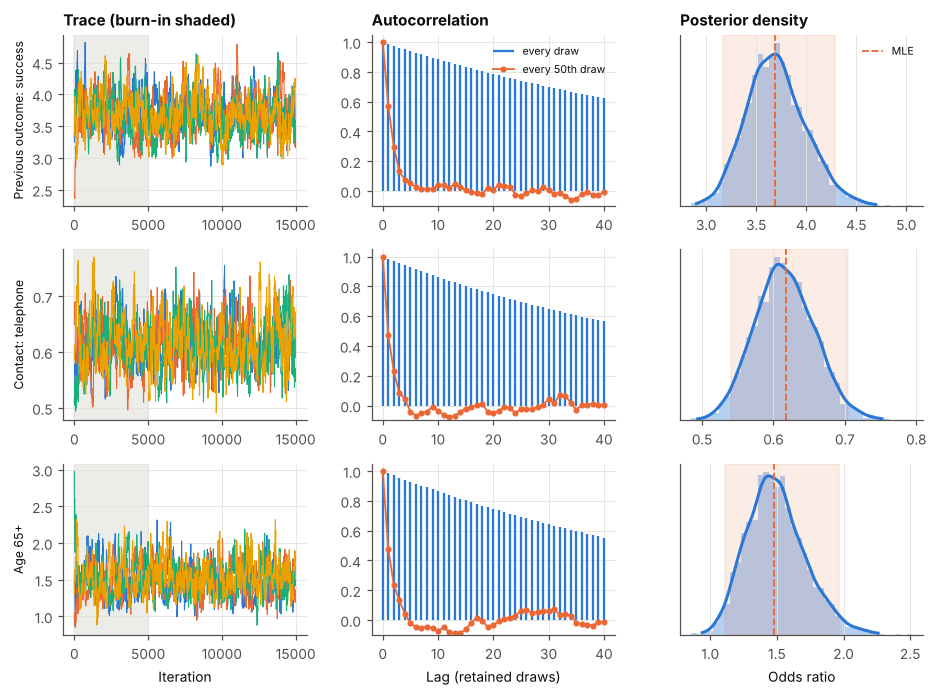

In [38]:
# Figure 7: trace, autocorrelation and density for three coefficients, on the odds-ratio scale
show = [("Previous outcome: success", 'C(poutcome, Treatment("nonexistent"))[T.success]'),
        ("Contact: telephone", "C(contact)[T.telephone]"),
        ("Age 65+", 'C(age_grp, Treatment("35-44"))[T.65+]')]
mle_params, mle_ci = logit_fit.params, logit_fit.conf_int()
chain_colors = [C_BLUE, C_ORANGE, C_AQUA, C_YELLOW]
fig, axes = plt.subplots(3, 3, figsize=(8.6, 6.4))
for r, (label, col) in enumerate(show):
    j = names.index(col)
    # trace: first 15,000 iterations of every chain, burn-in shaded
    for c in range(N_CHAINS):
        axes[r, 0].plot(np.arange(0, 15000, 10), np.exp(draws[:15000:10, c, j]), color=chain_colors[c], linewidth=0.7)
    axes[r, 0].axvspan(0, BURN, color=GRID, alpha=0.7, zorder=0)
    axes[r, 0].set_ylabel(label, fontsize=8)
    # autocorrelation of chain 1 in units of retained draws: every draw after burn-in vs draws thinned by THIN
    acf_all = acf(post[:, 0, j], 40)
    acf_thin = acf(kept[:, 0, j], 40)
    axes[r, 1].vlines(np.arange(41), 0, acf_all, color=C_BLUE, linewidth=1.5, label="every draw")
    axes[r, 1].plot(np.arange(41), acf_thin, "o-", color=C_ORANGE, markersize=3, linewidth=1.2, label=f"every {THIN}th draw")
    axes[r, 1].set_ylim(-0.1, 1.05)
    # density of the posterior with the MLE normal approximation
    flat = np.exp(kept[:, :, j].ravel())
    grid_x = np.linspace(np.quantile(flat, 0.001), np.quantile(flat, 0.999), 300)
    axes[r, 2].hist(flat, bins=40, density=True, color=C_BLUE, alpha=0.35)
    axes[r, 2].plot(grid_x, stats.gaussian_kde(flat)(grid_x), color=C_BLUE)
    axes[r, 2].axvline(np.exp(mle_params[col]), color=C_ORANGE, linestyle="--", linewidth=1.2, label="MLE")
    axes[r, 2].axvspan(np.exp(mle_ci.loc[col, 0]), np.exp(mle_ci.loc[col, 1]), color=C_ORANGE, alpha=0.12)
    axes[r, 2].set_yticks([])
axes[0, 0].set_title("Trace (burn-in shaded)", loc="left"); axes[0, 1].set_title("Autocorrelation", loc="left")
axes[0, 2].set_title("Posterior density", loc="left")
axes[0, 1].legend(fontsize=7, loc="upper right"); axes[0, 2].legend(fontsize=7, loc="upper right")
axes[2, 0].set_xlabel("Iteration"); axes[2, 1].set_xlabel("Lag (retained draws)"); axes[2, 2].set_xlabel("Odds ratio")
fig.tight_layout()
save(fig, "fig7_mcmc_diagnostics")

### 9.2.2 Posterior odds ratios compared with maximum likelihood

In [39]:
scale_back = np.array([1 / sd_b[c] if c in STD_COLS else 1.0 for c in names])
i_int, i_std = names.index("Intercept"), [names.index(c) for c in STD_COLS]

def to_original_units(draws_3d):
    """Undo the standardisation: slopes divide by the sd, and the intercept absorbs the centring."""
    flat_ = draws_3d.reshape(-1, len(names)) * scale_back
    flat_[:, i_int] -= flat_[:, i_std] @ mu_b[STD_COLS].values
    return flat_

coef_draws = to_original_units(kept)                              # coefficients in the original units
q = np.quantile(coef_draws, [0.025, 0.5, 0.975], axis=0)
cmp_tab = pd.DataFrame({
    "OR_MLE": np.exp(mle_params.values), "MLE_CI_low": np.exp(mle_ci[0].values), "MLE_CI_high": np.exp(mle_ci[1].values),
    "OR_Bayes": np.exp(q[1]), "CrI_low": np.exp(q[0]), "CrI_high": np.exp(q[2]),
    "R_hat": diag["R_hat"].values, "ESS": diag["ESS_kept"].values}, index=names)
cmp_tab.index = [clean_name(i) for i in cmp_tab.index]
cmp_tab = cmp_tab.drop(index="Intercept")
cmp_tab.round(4).to_csv("tables/bayes_logit_vs_mle.csv")
shift_se = (np.abs(coef_draws.mean(axis=0) - mle_params.values) / logit_fit.bse.values)
width_ratio = (q[2] - q[0]) / (mle_ci[1].values - mle_ci[0].values)
print(f"Largest gap between posterior mean and MLE: {shift_se.max():.2f} standard errors")
print(f"Credible-interval width relative to confidence-interval width: {width_ratio.min():.3f} to {width_ratio.max():.3f}")
excl_cri = (cmp_tab.CrI_low > 1) | (cmp_tab.CrI_high < 1)
excl_ci = (cmp_tab.MLE_CI_low > 1) | (cmp_tab.MLE_CI_high < 1)
print(f"Terms where the 95% CrI excludes 1: {int(excl_cri.sum())}; where the 95% CI excludes 1: {int(excl_ci.sum())} (of {len(cmp_tab)})")
print("Terms that differ:", list(cmp_tab.index[excl_cri != excl_ci]))
cmp_tab.loc[keep].round(3)

Largest gap between posterior mean and MLE: 0.11 standard errors
Credible-interval width relative to confidence-interval width: 0.962 to 1.044
Terms where the 95% CrI excludes 1: 20; where the 95% CI excludes 1: 21 (of 46)
Terms that differ: ['Age 55-64']


,OR_MLE,MLE_CI_low,MLE_CI_high,OR_Bayes,CrI_low,CrI_high,R_hat,ESS
Previous outcome: success,3.684,3.166,4.287,3.686,3.170,4.326,1.000,1355.758
Previous outcome: failure,0.631,0.559,0.711,0.627,0.556,0.708,1.001,1498.459
Contact: telephone,0.617,0.541,0.704,0.614,0.536,0.700,1.001,1483.032
Age 17-24,1.302,1.034,1.639,1.301,1.032,1.637,1.002,1619.082
Age 25-34,1.134,1.023,1.258,1.133,1.022,1.249,1.000,1662.992
Age 45-54,1.094,0.972,1.231,1.092,0.968,1.227,1.001,1537.222
Age 55-64,1.179,1.004,1.386,1.177,0.994,1.380,1.000,1424.121
Age 65+,1.479,1.112,1.968,1.477,1.114,1.974,1.000,1681.986
Job: student,1.146,0.907,1.448,1.152,0.908,1.442,1.002,1596.237
Job: retired,1.170,0.928,1.476,1.169,0.926,1.475,1.001,1512.170


In [40]:
# Probability statements that only the posterior can give (Lecture 6), on the original scale
def p_gt(col, value=1.0):
    return (np.exp(coef_draws[:, names.index(col)]) > value).mean()
print(f"P(OR for previous success > 3) = {p_gt(show[0][1], 3):.3f}")
print(f"P(OR for age 65+ > 1)          = {p_gt(show[2][1]):.3f}")
col_1724 = 'C(age_grp, Treatment("35-44"))[T.17-24]'
print(f"P(OR for 17-24 > 1)            = {p_gt(col_1724):.3f}")
print(f"P(OR for telephone < 0.7)      = {1 - p_gt(show[1][1], 0.7):.3f}")

P(OR for previous success > 3) = 0.996
P(OR for age 65+ > 1)          = 0.996
P(OR for 17-24 > 1)            = 0.987
P(OR for telephone < 0.7)      = 0.973


### 9.2.3 Sensitivity to the prior
The prior is now tightened to Normal(0, 0.5²), which allows odds ratios of about 0.4 to 2.7 at 95% prior probability. If the large training set dominates the prior (Lecture 6), the posterior should barely move.

In [41]:
t0 = time.time()
draws_tight, acc_tight = run_mh(0.5, 2, 30000, SEED + 1)
tight = to_original_units(draws_tight[3000::10])
shift_tight = np.abs(tight.mean(axis=0) - coef_draws.mean(axis=0)) / logit_fit.bse.values
big = pd.Series(shift_tight, index=[clean_name(i) for i in names]).drop("Intercept").sort_values(ascending=False)
print(f"Tight-prior run: 2 chains x 30,000 iterations in {time.time() - t0:.0f} s, acceptance {np.round(acc_tight, 3)}")
print(f"Largest shift in a posterior mean: {shift_tight.max():.2f} standard errors; median shift {np.median(shift_tight):.3f}")
print("Terms that move most (standard errors):")
print(big.head(5).round(2))
key_terms = ["Previous outcome: success", "Contact: telephone", "Age 65+", "Age 17-24", "log2_campaign"]
print("Shift for the terms used in the business insights (standard errors):")
print(big.loc[key_terms].round(2))

Tight-prior run: 2 chains x 30,000 iterations in 73 s, acceptance [0.227 0.225]
Largest shift in a posterior mean: 1.06 standard errors; median shift 0.235
Terms that move most (standard errors):
Month: aug    1.06
Month: jul    1.05
Month: mar    0.99
Month: jun    0.94
Month: nov    0.94
dtype: float64
Shift for the terms used in the business insights (standard errors):
Previous outcome: success    0.30
Contact: telephone           0.56
Age 65+                      0.13
Age 17-24                    0.17
log2_campaign                0.01
dtype: float64


**Result.** The four chains agree: the largest R-hat is 1.003 and the smallest ESS is 1,199 out of 4,400 retained draws, with acceptance rates near 0.24. The trace plots show the chains forgetting their dispersed starting values within the burn-in. Autocorrelation is high for consecutive iterations (above 0.9) and falls to about 0.5 after thinning by 50, so thinning by 50 leaves draws that are far less dependent.

* **Agreement with MLE.** Posterior medians of the odds ratios match the maximum likelihood odds ratios; the largest gap in a posterior mean is 0.11 standard errors. Credible intervals are 0.96 to 1.04 times as wide as the confidence intervals. With 32,934 customers and a weak prior, the likelihood dominates the posterior. Only one of 46 terms changes status at the 5% level (Age 55-64: lower confidence limit 1.004, lower credible limit 0.994).
* **What the posterior adds.** A 95% credible interval is a probability statement about the odds ratio, and any derived probability comes directly from the draws. For example, P(OR for previous success > 3) = 0.996 and P(OR for age 65+ > 1) = 0.996. A confidence interval cannot be read this way.
* **Prior sensitivity.** With the tighter Normal(0, 0.5²) prior the posterior mean of every coefficient moves by at most 1.1 standard errors (median 0.24). The largest shifts are for month effects, which are large coefficients that the tight prior shrinks. The terms used in the business insights move by 0.6 standard errors or less (previous success 0.30, telephone 0.56, age 65+ 0.13).
* **Trade-offs (Lecture 6).** The Bayesian fit needs a prior, a sampler, a convergence check and several minutes of computation, while the MLE takes a fraction of a second. In return it carries prior knowledge, gives probability statements, and shows how sensitive the conclusions are to the prior. For this large data set the MLE is an adequate summary, and the Bayesian fit confirms it.

## 10. Business insight calculations

In [42]:
# Insight: contact intensity
camp = df.assign(calls=df["campaign"].clip(upper=6).astype(int).astype(str).replace({"6": "6+"})).groupby("calls")["target"].agg(["size", "mean"]).round(3)
print("Subscription rate by number of calls in this campaign:\n", camp)
share_after3 = (df["campaign"] > 3).mean()
subs_after3 = df.loc[df["campaign"] > 3, "target"].sum() / df["target"].sum()
print(f"Calls beyond the 3rd attempt: {share_after3:.1%} of customers, {subs_after3:.1%} of subscribers")

Subscription rate by number of calls in this campaign:
         size   mean
calls              
1      17629  0.130
2      10566  0.115
3       5339  0.108
4       2650  0.094
5       1599  0.075
6+      3385  0.055
Calls beyond the 3rd attempt: 18.5% of customers, 12.0% of subscribers


In [43]:
# Insight: previous success customers
ps = df[df.poutcome == "success"]
print(f"Previous-success customers: n = {len(ps)} ({len(ps)/len(df):.1%} of base), rate = {ps.target.mean():.1%}, share of all subscribers = {ps.target.sum()/df.target.sum():.1%}")

Previous-success customers: n = 1371 (3.3% of base), rate = 65.1%, share of all subscribers = 19.2%


In [44]:
# Insight: calls saved by targeting with gradient boosting at different coverage levels (test set)
for frac in [0.2, 0.3, 0.5]:
    cap, hit = top_capture(yte, test_pred["Gradient boosting"], frac)
    print(f"Call top {frac:.0%}: reach {cap:.1%} of subscribers, hit rate {hit:.1%} (vs {yte.mean():.1%} calling everyone); calls avoided {1-frac:.0%}")

Call top 20%: reach 66.0% of subscribers, hit rate 37.2% (vs 11.3% calling everyone); calls avoided 80%
Call top 30%: reach 73.1% of subscribers, hit rate 27.4% (vs 11.3% calling everyone); calls avoided 70%
Call top 50%: reach 82.6% of subscribers, hit rate 18.6% (vs 11.3% calling everyone); calls avoided 50%


## 11. Fairness check by age group (used in the ethics section)
Who would be on a top-20% call list built by the gradient boosting model? Selection rate by age group on the test set, compared with each group's share of customers and its actual subscription rate.

In [45]:
fair_tabs = []
for name in ["Logistic regression", "Gradient boosting"]:
    p_m = test_pred[name]
    sel_flag = p_m >= np.quantile(p_m, 0.8)
    f = pd.DataFrame({"age_grp": test["age_grp"].values, "selected": sel_flag, "y": yte}).groupby("age_grp").agg(
        n=("y", "size"), actual_rate=("y", "mean"), selected_rate=("selected", "mean")).loc[AGE_LABELS]
    f["share_of_customers"] = f["n"] / f["n"].sum()
    f["share_of_call_list"] = f["selected_rate"] * f["n"] / sel_flag.sum()
    f.insert(0, "model", name)
    fair_tabs.append(f)
fair = pd.concat(fair_tabs)
fair.round(3).to_csv("tables/fairness_age.csv")
fair.round(3)

,model,n,actual_rate,selected_rate,share_of_customers,share_of_call_list
age_grp,,,,,,
17-24,Logistic regression,182,0.269,0.544,0.022,0.060
25-34,Logistic regression,2757,0.127,0.230,0.335,0.384
35-44,Logistic regression,2709,0.090,0.140,0.329,0.230
45-54,Logistic regression,1759,0.072,0.131,0.214,0.140
55-64,Logistic regression,682,0.135,0.238,0.083,0.098
65+,Logistic regression,145,0.455,0.986,0.018,0.087
17-24,Gradient boosting,182,0.269,0.593,0.022,0.066
25-34,Gradient boosting,2757,0.127,0.234,0.335,0.391
35-44,Gradient boosting,2709,0.090,0.128,0.329,0.210


## 12. Hypothesis summary

In [46]:
o = or_tab
hyp = pd.DataFrame([
    {"hypothesis": "H1: customers under 25 and 65+ have higher odds than 35-44 (adjusted)",
     "test": "Wald z in M4; LRT for the age block",
     "result": f"17-24 OR {o.loc['Age 17-24','OR']:.2f} [{o.loc['Age 17-24','CI_low']:.2f}, {o.loc['Age 17-24','CI_high']:.2f}]; 65+ OR {o.loc['Age 65+','OR']:.2f} [{o.loc['Age 65+','CI_low']:.2f}, {o.loc['Age 65+','CI_high']:.2f}]; age block LRT p = {lrt('M4 without age', 'M4 + timing')[2]:.4f}"},
    {"hypothesis": "H2: previous campaign success is the strongest customer-level predictor",
     "test": "Odds ratios in M4; permutation importance",
     "result": f"Previous success OR {o.loc['Previous outcome: success','OR']:.2f} [{o.loc['Previous outcome: success','CI_low']:.2f}, {o.loc['Previous outcome: success','CI_high']:.2f}], largest customer-level OR; nr_employed dominates overall importance"},
    {"hypothesis": "H3: cellular contact raises the odds, and the channel effect depends on previous outcome",
     "test": "Wald z; LRT for contact x poutcome",
     "result": f"Telephone OR {o.loc['Contact: telephone','OR']:.2f} [{o.loc['Contact: telephone','CI_low']:.2f}, {o.loc['Contact: telephone','CI_high']:.2f}]; interaction LRT p = {lrt('M4 + timing', 'M5 + contact x previous outcome')[2]:.2f} (not supported)"},
    {"hypothesis": "H4: more calls in the same campaign lower the odds",
     "test": "Wald z for log2_campaign",
     "result": f"OR per doubling {o.loc['log2_campaign','OR']:.2f} [{o.loc['log2_campaign','CI_low']:.2f}, {o.loc['log2_campaign','CI_high']:.2f}]"},
    {"hypothesis": "H5: a non-parametric model ranks customers better than logistic regression",
     "test": "Paired t-test on CV fold AUCs; bootstrap CI on test AUC difference; phase-3 test",
     "result": f"GB - LR test AUC {diffs.mean():+.3f}, 95% CI [{boot_ci[0]:+.3f}, {boot_ci[1]:+.3f}]; phase-3 AUC GB {temporal['Gradient boosting']:.3f} vs LR {temporal['Logistic regression']:.3f}"},
])
hyp.to_csv("tables/hypotheses.csv", index=False)
hyp

,hypothesis,test,result
0,H1: customers under 25 and 65+ have higher odds than 35-44 (adjusted),Wald z in M4; LRT for the age block,"17-24 OR 1.30 [1.03, 1.64]; 65+ OR 1.48 [1.11, 1.97]; age block LRT p = 0.0183"
1,H2: previous campaign success is the strongest customer-level predictor,Odds ratios in M4; permutation importance,"Previous success OR 3.68 [3.17, 4.29], largest customer-level OR; nr_employed dominates overall importance"
2,"H3: cellular contact raises the odds, and the channel effect depends on previous outcome",Wald z; LRT for contact x poutcome,"Telephone OR 0.62 [0.54, 0.70]; interaction LRT p = 0.94 (not supported)"
3,H4: more calls in the same campaign lower the odds,Wald z for log2_campaign,"OR per doubling 0.93 [0.89, 0.97]"
4,H5: a non-parametric model ranks customers better than logistic regression,Paired t-test on CV fold AUCs; bootstrap CI on test AUC difference; phase-3 test,"GB - LR test AUC +0.007, 95% CI [-0.000, +0.015]; phase-3 AUC GB 0.647 vs LR 0.674"


In [47]:
# Key numbers used in the report, collected in one place
key = {
    "rows_raw": len(raw), "rows_clean": len(df), "base_rate": round(p0, 4),
    "auc_leak_with_duration": round(leak_with, 3), "auc_leak_without_duration": round(leak_without, 3),
    "test_auc_lr": round(test_tab.loc["Logistic regression", "Test ROC-AUC"], 3),
    "test_auc_gb": round(test_tab.loc["Gradient boosting", "Test ROC-AUC"], 3),
    "boot_diff_ci": [round(x, 4) for x in boot_ci],
    "spearman_volume_rate": round(rho, 2),
    "mcmc_max_rhat": round(float(diag["R_hat"].max()), 3), "mcmc_min_ess": int(diag["ESS_kept"].min()),
}
key

{'rows_raw': 41180,
 'rows_clean': 41168,
 'base_rate': np.float64(0.1126),
 'auc_leak_with_duration': 0.932,
 'auc_leak_without_duration': 0.787,
 'test_auc_lr': np.float64(0.8),
 'test_auc_gb': np.float64(0.807),
 'boot_diff_ci': [np.float64(-0.0003), np.float64(0.0149)],
 'spearman_volume_rate': np.float64(-0.67),
 'mcmc_max_rhat': 1.003,
 'mcmc_min_ess': 1199}